# 01 — Data Check
**Part A | Milestone 1**

Goal: confirm the raw EuRoC data loads correctly, look at what the raw
signals actually look like, and compare the two easy sequences before doing
anything else with them.

Run `python scripts/verify_data.py` from the terminal first — this notebook
assumes that already passed.

In [7]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import yaml
import numpy as np
import matplotlib.pyplot as plt

from vio_drift.data.loader import load_sequence
from vio_drift.data.align import report_gaps

config = yaml.safe_load((Path.cwd().parent / "configs" / "config.yaml").read_text())
raw_dir = Path.cwd().parent / config["data"]["raw_dir"]
sequences = config["data"]["sequences"]
sequences

['MH_01_easy', 'MH_02_easy']

## Load both sequences

We load IMU + ground truth for each sequence and print how many rows we
got and the implied sampling rate — this should be close to 200 Hz for
IMU on every sequence.

In [8]:
loaded = {}
for seq_name in sequences:
    imu_df, gt_df = load_sequence(raw_dir, seq_name)
    loaded[seq_name] = (imu_df, gt_df)
    gaps = report_gaps(imu_df, gt_df)
    print(f"{seq_name}: {len(imu_df)} IMU rows, {len(gt_df)} GT rows")
    print(f"   IMU rate ~{gaps['imu']['implied_rate_hz']:.1f} Hz, "
          f"GT rate ~{gaps['ground_truth']['implied_rate_hz']:.1f} Hz")
    print(f"   duration ~{gaps['imu']['duration_s']:.1f} s\n")

MH_01_easy: 36820 IMU rows, 36382 GT rows
   IMU rate ~200.0 Hz, GT rate ~200.0 Hz
   duration ~184.1 s

MH_02_easy: 30400 IMU rows, 29993 GT rows
   IMU rate ~200.0 Hz, GT rate ~200.0 Hz
   duration ~152.0 s



## Raw IMU signals — one sequence

Plot gyro and accel for the first sequence, first 10 seconds, so we can
see what "normal" motion looks like before checking the other sequence.

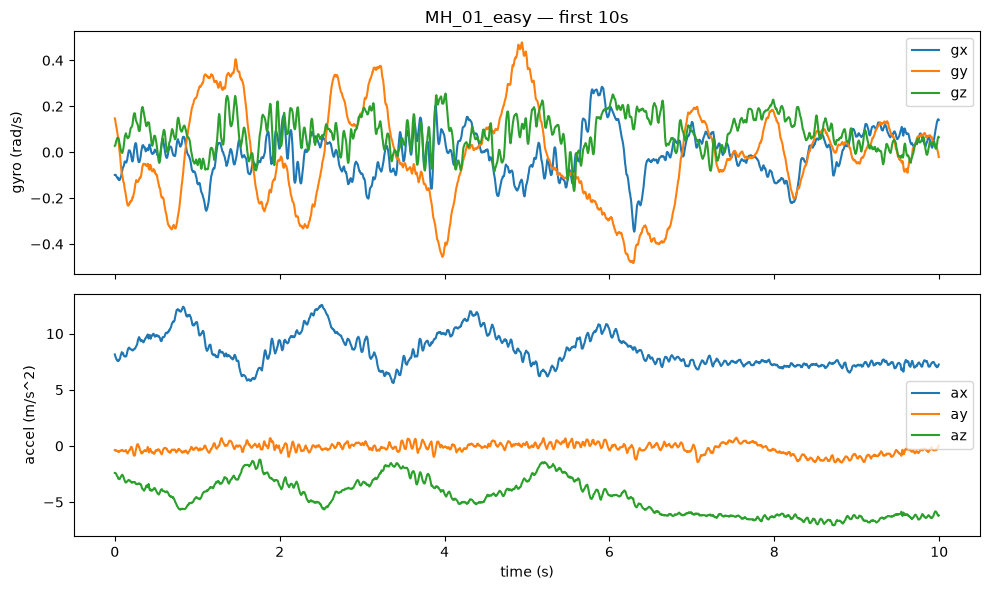

In [9]:
seq_name = sequences[0]
imu_df, gt_df = loaded[seq_name]

t = (imu_df["t_ns"] - imu_df["t_ns"].iloc[0]) / 1e9
mask = t < 10  # first 10 seconds

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for col in ["gx", "gy", "gz"]:
    axes[0].plot(t[mask], imu_df.loc[mask, col], label=col)
axes[0].set_ylabel("gyro (rad/s)")
axes[0].legend()
axes[0].set_title(f"{seq_name} — first 10s")

for col in ["ax", "ay", "az"]:
    axes[1].plot(t[mask], imu_df.loc[mask, col], label=col)
axes[1].set_ylabel("accel (m/s^2)")
axes[1].set_xlabel("time (s)")
axes[1].legend()

plt.tight_layout()
plt.savefig(Path.cwd().parent / "figures" / "eda" / "raw_imu_signals.png", dpi=150)
plt.show()

**Sanity check:** a flying MAV is constantly tilting, so gravity does NOT sit on a single
axis — it is split across `ax`, `ay`, `az` depending on the drone's orientation.
The correct check is the **combined magnitude** `sqrt(ax^2 + ay^2 + az^2)`, which should
hover near 9.81 m/s^2 whenever the drone is not accelerating hard. If it sits near 0 or
far from 9.81 across the whole sequence, something is off in how the file was read.

In [10]:
accel_mag = np.sqrt(imu_df['ax']**2 + imu_df['ay']**2 + imu_df['az']**2)
print(f"accel magnitude: mean={accel_mag.mean():.3f}, std={accel_mag.std():.3f} m/s^2")

accel magnitude: mean=9.805, std=1.294 m/s^2


## True 3D trajectory — both sequences

Compare the flight paths of MH_01_easy and MH_02_easy. Both are "easy" sequences, so
similar overall shapes are expected.

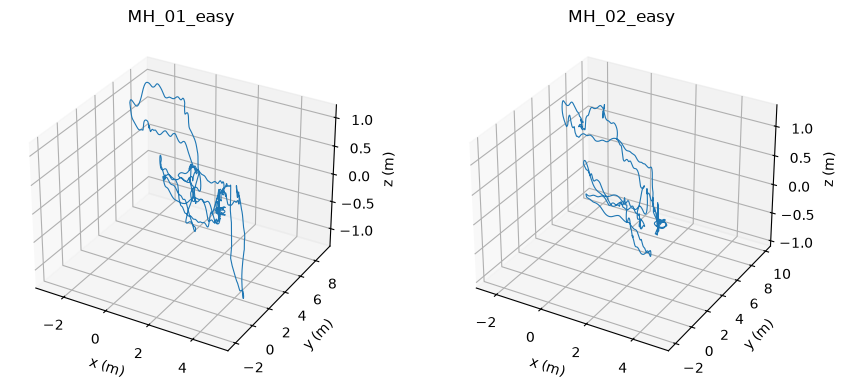

In [11]:
fig = plt.figure(figsize=(9, 4))
for i, seq_name in enumerate(sequences):
    _, gt_df = loaded[seq_name]
    ax = fig.add_subplot(1, len(sequences), i + 1, projection="3d")
    ax.plot(gt_df["px"], gt_df["py"], gt_df["pz"], linewidth=0.8)
    ax.set_title(seq_name)
    ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)"); ax.set_zlabel("z (m)")

plt.tight_layout()
plt.savefig(Path.cwd().parent / "figures" / "eda" / "true_trajectories.png", dpi=150)
plt.show()

## Speed over time — both sequences

Derived from consecutive ground-truth positions. Similar speed profiles are expected
since both sequences are "easy"; note any visible differences below.

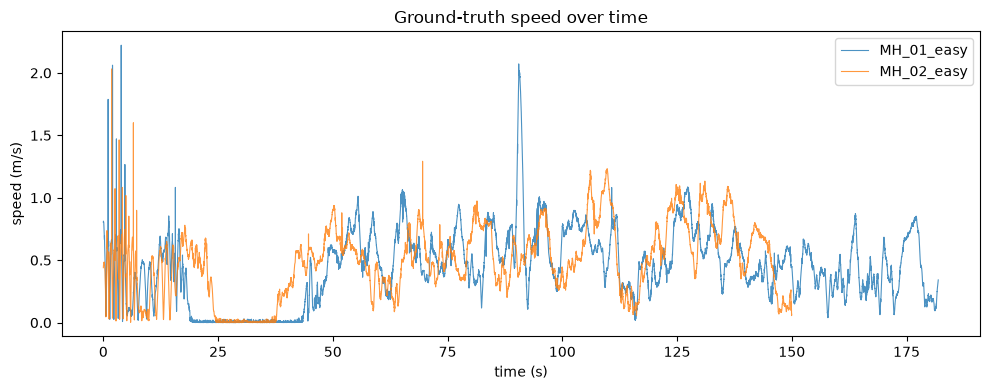

In [12]:
fig, ax = plt.subplots(figsize=(10, 4))
for seq_name in sequences:
    _, gt_df = loaded[seq_name]
    t = (gt_df["t_ns"] - gt_df["t_ns"].iloc[0]) / 1e9
    dp = gt_df[["px", "py", "pz"]].diff()
    dt = gt_df["t_ns"].diff() / 1e9
    speed = np.sqrt((dp["px"]**2 + dp["py"]**2 + dp["pz"]**2)) / dt
    ax.plot(t, speed, label=seq_name, alpha=0.8, linewidth=0.8)

ax.set_xlabel("time (s)")
ax.set_ylabel("speed (m/s)")
ax.legend()
ax.set_title("Ground-truth speed over time")
plt.tight_layout()
plt.savefig(Path.cwd().parent / "figures" / "eda" / "speed_comparison.png", dpi=150)
plt.show()

## Summary

Both Machine Hall **easy** sequences load cleanly and are usable for Phase 1.

- **Sampling.** IMU and ground truth are both **200 Hz**. MH_01_easy is 184.1 s (36 820 IMU rows); MH_02_easy is 152.0 s (30 400 IMU rows). The largest IMU timestamp step is 5.0 ms — there are no large gaps.
- **Missing values.** None in either stream.
- **How the flights differ.** MH_02 is shorter. Mean speed is similar (0.44 m/s vs 0.49 m/s); MH_01 has the higher peak (~2.0 m/s vs ~1.2 m/s). Trajectories occupy a comparable hall volume.
- **Raw IMU.** Individual accel axes do **not** sit at \(\pm 9.81\) because the MAV is tilted; that is expected. The vector magnitude is **9.80 m/s\(^2\)** (std ~1.3) on both flights, consistent with gravity plus motion. Gyro over the first 10 s is small-amplitude chatter (~0.2 rad/s), not aggressive rotation.

No column-mapping or unit issues showed up. Safe to proceed to label construction and EDA.